# Stochastic Gradient Descent

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hamedheli/ml-from-scratch/blob/main/03-gradient-descent/sgd.ipynb) [![View in nbviewer](https://img.shields.io/badge/view%20in-nbviewer-orange)](https://nbviewer.org/github/HamedHeli/ml-from-scratch/blob/main/03-gradient-descent/sgd.ipynb)

Part of [Machine Learning From Scratch](../README.md). The code for this model is in this folder; shared helpers (data loading, plotting, loss functions) are in [`common/`](../common).


## Setup

In [1]:
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    # On Colab, get the code and data from GitHub first
    if not Path("/content/ml-from-scratch").exists():
        !git clone -q https://github.com/hamedheli/ml-from-scratch.git /content/ml-from-scratch
    ROOT = Path("/content/ml-from-scratch")
else:
    ROOT = Path.cwd().resolve().parent  # this notebook sits in one model folder

# shared helpers, plus the model folders this notebook uses
for folder in ["common", "03-gradient-descent"]:
    sys.path.insert(0, str(ROOT / folder))


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from utils import load_trainval, standardize_cols
from fun_obj import LeastSquaresLoss
from linear_models import LinearModel
from optimizers import GradientDescent, GradientDescentLineSearch, StochasticGradient
from learning_rate_getters import ConstantLR, InverseLR, InverseSquaredLR, InverseSqrtLR

plt.rcParams["figure.figsize"] = (7, 5)
np.random.seed(0)  # makes the random initializations (and the numbers quoted below) reproducible


Gradient descent updates the parameters with $w^{t+1} = w^t - \alpha^t \nabla f(w^t)$. When $f$ is a sum over $n$ training examples, each full gradient costs $O(nd)$. Stochastic gradient descent (SGD) uses the gradient on a small random mini-batch instead. Each step is much cheaper and is correct on average, but it is noisy. Because of the noise, SGD with a fixed step size does not converge, so the step size has to shrink over time. This section compares four ways of shrinking it.

**What I implemented** ([`fun_obj.py`](../common/fun_obj.py), [`optimizers.py`](optimizers.py), [`learning_rate_getters.py`](learning_rate_getters.py))
* Loss functions as objects that return both the value and the gradient (least squares, logistic, softmax, ...), with a finite-difference check of the gradient (`FunObj.check_correctness`).
* `GradientDescent`, and `GradientDescentLineSearch`, which chooses the step size with an Armijo backtracking line search.
* `StochasticGradient`, which shuffles the data each epoch, splits it into mini-batches, and takes one gradient step per batch.
* Learning-rate schedules $\alpha^t = c$, $c/t$, $c/t^2$ and $c/\sqrt{t}$, where $t$ counts mini-batch steps.

**Experiment:** least-squares linear regression on the `dynamics` dataset (10,001 training examples, 5 standardized features), with mini-batches of 10, $c = 0.1$ and 50 epochs. Each plot shows the full training objective after every epoch.

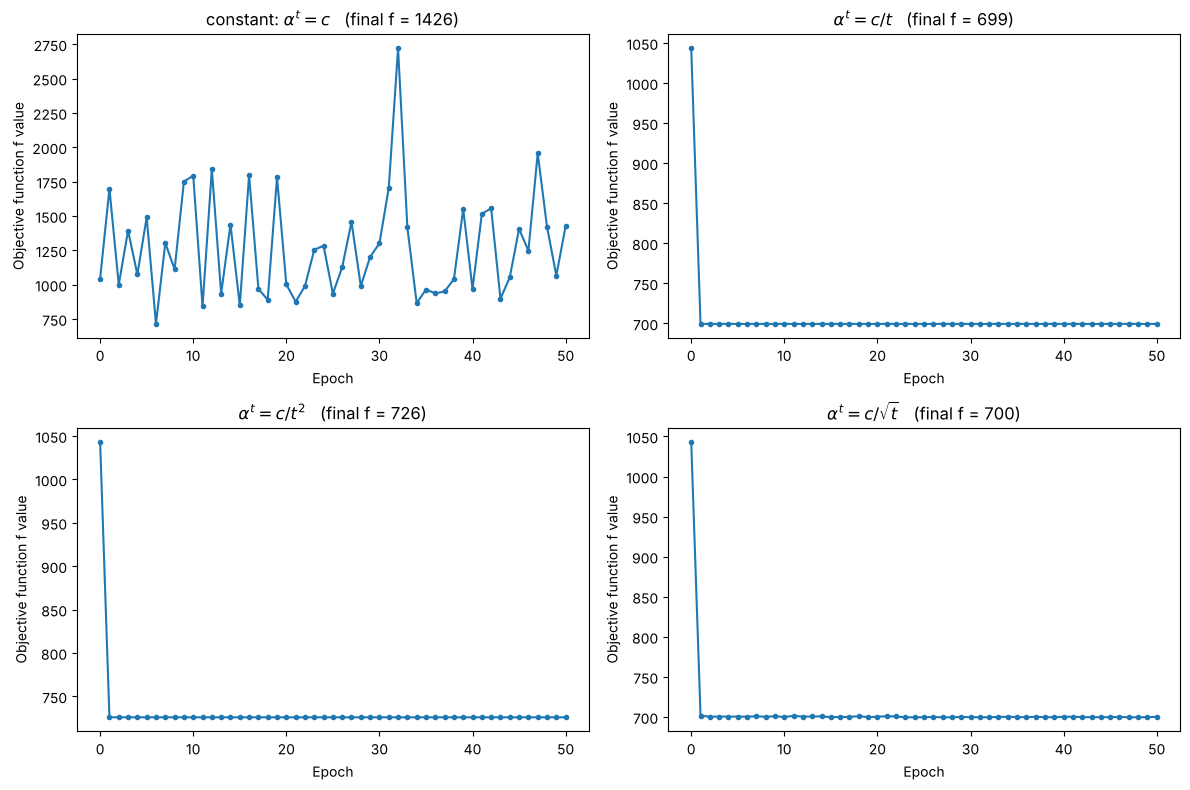

In [3]:
X_train_orig, y_train, X_val_orig, y_val = load_trainval("dynamics.pkl")
X_train, mu, sigma = standardize_cols(X_train_orig)
X_val, _, _ = standardize_cols(X_val_orig, mu, sigma)

loss = LeastSquaresLoss()
c= 0.1
learning_rate_CLR = ConstantLR(c)
learning_rate_ILR = InverseLR(c)
learning_rate_ISLR = InverseSquaredLR(c)
learning_rate_ISqrtLR = InverseSqrtLR(c)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (learning_rate, names) in zip(axes.flat,
                                [(learning_rate_CLR, r"constant: $\alpha^t = c$"),
                                (learning_rate_ILR, r"$\alpha^t = c/t$"),
                                (learning_rate_ISLR, r"$\alpha^t = c/t^2$"),
                                (learning_rate_ISqrtLR, r"$\alpha^t = c/\sqrt{t}$")]):
    optimizer = StochasticGradient (learning_rate_getter=learning_rate,
                                batch_size=10,
                                base_optimizer=GradientDescent(),
                                max_evals= 50)
    model  = LinearModel(loss, optimizer)
    model.fit(X_train, y_train)
    ax.plot(model.fs, marker="o", markersize=3)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Objective function f value")
    ax.set_title(f"{names}   (final f = {model.fs[-1]:.0f})")
fig.tight_layout()
plt.show()

* **Constant $c$:** the objective jumps around, roughly between 700 and 2,700, and never settles. With a fixed step, the mini-batch noise never averages out.
* **$c/t$:** reaches about 699 within the first epoch and stays there.
* **$c/t^2$:** freezes at about 726, above the minimum. The step sizes shrink so fast that their sum, $\sum_t c/t^2 = c\pi^2/6$, is finite. The parameters can only travel a bounded distance, so they stop before reaching the minimum.
* **$c/\sqrt{t}$:** reaches about 700, with a little noise left because its steps shrink more slowly than $c/t$.

This matches the standard conditions for SGD to converge. The first is $\sum_t \alpha^t = \infty$, so the steps are large enough to reach the minimum from anywhere. The second is $\sum_t (\alpha^t)^2 < \infty$, so the noise eventually dies out. $c/t$ satisfies both. A constant step fails the second condition and $c/t^2$ fails the first. $c/\sqrt{t}$ fails the second in theory, but its steps are still small enough by the end that it works well in practice.